In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import os
import tensorflow as tf
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 unused import
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from sklearn.manifold import TSNE

# local imports 
from pwa import PWA
from tools import *
from rietools import *
from bdiff import *

np.random.seed(123)
tf.set_random_seed(123)
Modes = tf.estimator.ModeKeys

In [ ]:
def trainer(opts,data,visdata_train,visdata_test,epoch,nr_samples,shuffle):
    #model
    model = PWA(opts)
    batch_size = opts['batch_size']
    #training loop
    for ep in range(epoch):
        if shuffle:
            np.random.shuffle(data)
        for iter in tqdm(range(nr_samples // batch_size)):
            #obtain a mini-batch
            batch = data[iter*batch_size:(iter+1)*batch_size,:]
            loss, mloss, rloss, kloss, mu, sigma= model.run_single_step(batch)
 
        print('[Epoch {}] Recon Loss: {}, MMD: {}'.format(ep,loss,mloss))
        print('Mean: {}, "Var": {}'.format(mu,np.exp(0.5*sigma)))
        if opts['dataset'] == 'bd':
            subset_len = 1
            #draw_means(opts,visdata_train,model,treedepth=opts['treedepth'],
            #                 b=2,c=opts['c'],d=opts['input_dim'],subset_len=5)
            draw_latent_tree(opts,visdata_train,model,treedepth=opts['treedepth'],
                             b=2,c=opts['c'],d=opts['input_dim'],subset_len=1,plot_means=False)
            #draw_latent_tree(opts,visdata_test,model,treedepth=opts['treedepth'],
            #                 b=2,c=opts['c'],d=opts['input_dim'],subset_len=1,plot_means=False)

            
            z_test = model.transformer_mu(np.reshape(visdata_test[0:subset_len],[-1,opts['input_dim']]))
            data_u_tree = visdata_train[0:subset_len]
            data_v_tree = np.reshape(z_test,[subset_len,opts['b']**(opts['treedepth']+1),opts['c'],opts['dim_z']])
            avg_dist_tree = np_compute_avg_distortion_tree(data_u_tree, data_v_tree, b=opts['b'], treedepth=opts['treedepth'], c=opts['c'])

            data_u = np.reshape(visdata_test[0:subset_len],[-1,opts['input_dim']])[0:20]
            data_v = z_test[0:20]
            avg_dist_all = np_compute_avg_distortion_all(data_u, data_v)
            print('Average distortion: Tree: {}, All, {}'.format(avg_dist_tree, avg_dist_all))
        else:
            z_test = model.transformer_mu(np.reshape(visdata_test,[-1,opts['input_dim']]))
            data_u = np.reshape(visdata_test,[-1,opts['input_dim']])
            data_v = z_test
            avg_dist_all = np_compute_avg_distortion_all(data_u, data_v)
            print('Average distortion: All, {}'.format(avg_dist_all))
            
    print('Done!')
    return model

In [ ]:
def load_wordnet_data(name):
    embeddings = np.load('./data/'+name+'.npy')
    np.random.shuffle(embeddings)
    N = len(embeddings)
    split = np.int(np.floor(0.8*N))
    embeddings_train = embeddings[:split]
    embeddings_test = embeddings[split:]
    return embeddings_train, embeddings_test

{'input_dim': 50, 'dec_mlr': False, 'nn_act_fn': <function relu at 0x7fb4f53b1950>, 'prior_var': 1.7, 'c': 5, 'lambda_mmd': 1.0, 'enc_act_sigma': None, 'mmd_q': 1, 'enc_act_mu': None, 'b': 2, 'hyp_c': 1.0, 'lr_rsgd': 0.001, 'recon_weight': 1.0, 'loss': 'l2', 'treedepth': 6, 'beta_kld': 10.0, 'lr_adam': 0.001, 'init_bias': 0.0, 'reparam_eucl': True, 'dataset': 'bd', 'batch_size': 64, 'use_expmap': True, 'scalar_dispersion': True, 'sigma_mmd': 1.0, 'beta_mmd': 10.0, 'nw_type': 'simple', 'init_std': 0.01, 'varregnorm': 2, 'hyp_var': False, 'dim_z': 2}
Generating trees...
Done
Instructions for updating:
Use keras.layers.dense instead.
Instructions for updating:
Colocations handled automatically by placer.

For more information, please see:
  * https://github.com/tensorflow/community/blob/master/rfcs/20180907-contrib-sunset.md
  * https://github.com/tensorflow/addons
If you depend on functionality not listed there, please file an issue.

Instructions for updating:
The TensorFlow Distributio

100%|██████████| 100/100 [00:02<00:00, 35.47it/s]


[Epoch 0] Recon Loss: 1974.8876953125, MMD: 0.06913378834724426
Mean: [-0.45835114  0.36495432], "Var": [0.43448952]


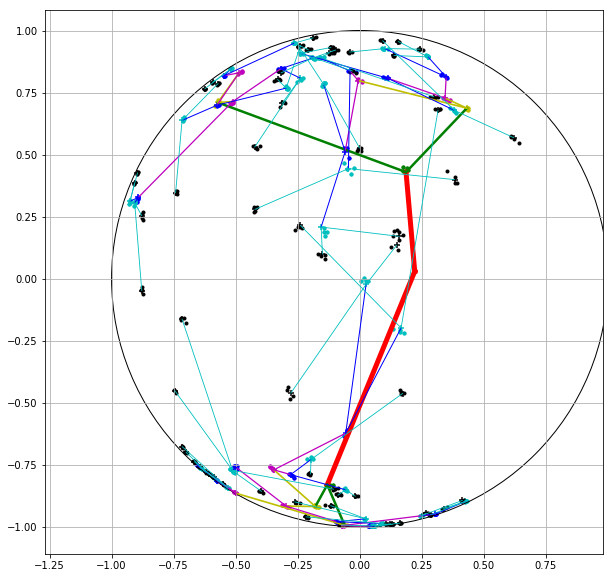

/local/home/oivan/projects/pwa/bdiff.py:337: RuntimeWarning: divide by zero encountered in true_divide
  return np.mean(np.abs(d_v-d_u)/d_u)
/local/home/oivan/projects/pwa/bdiff.py:337: RuntimeWarning: invalid value encountered in true_divide
  return np.mean(np.abs(d_v-d_u)/d_u)
 20%|██        | 20/100 [00:00<00:00, 190.12it/s]

Average distortion: Tree: 0.60234135389328, All, nan


100%|██████████| 100/100 [00:00<00:00, 171.26it/s]


[Epoch 1] Recon Loss: 1903.238525390625, MMD: 0.05050276964902878
Mean: [-0.28530952  0.6484827 ], "Var": [0.30126306]


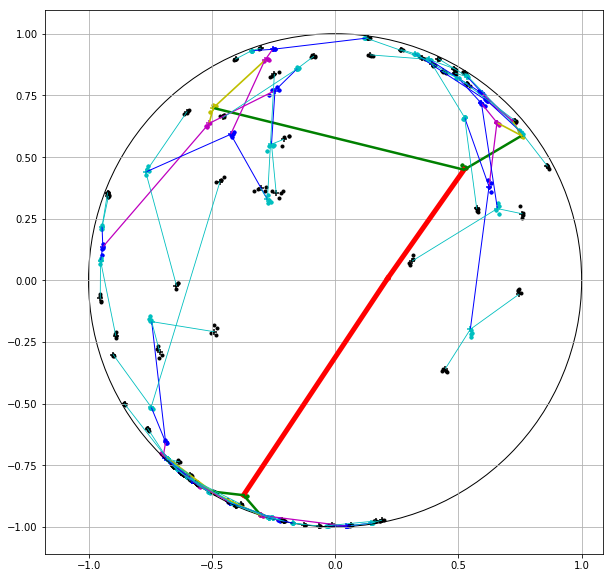

 17%|█▋        | 17/100 [00:00<00:00, 167.29it/s]

Average distortion: Tree: 0.5482912659645081, All, nan


100%|██████████| 100/100 [00:00<00:00, 171.85it/s]


[Epoch 2] Recon Loss: 1867.087646484375, MMD: 0.07805516570806503
Mean: [-0.18198314  0.6818571 ], "Var": [0.28025413]


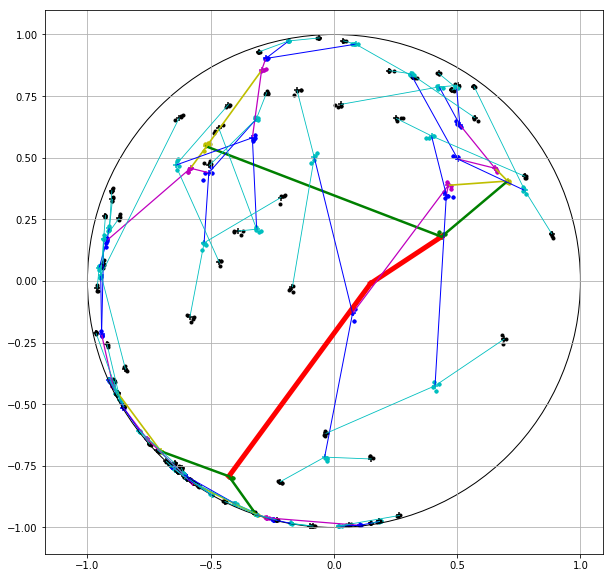

 13%|█▎        | 13/100 [00:00<00:00, 122.85it/s]

Average distortion: Tree: 0.5724503397941589, All, nan


100%|██████████| 100/100 [00:00<00:00, 158.61it/s]


[Epoch 3] Recon Loss: 1837.1558837890625, MMD: 0.07081924378871918
Mean: [-0.06143323  0.7395717 ], "Var": [0.2670349]


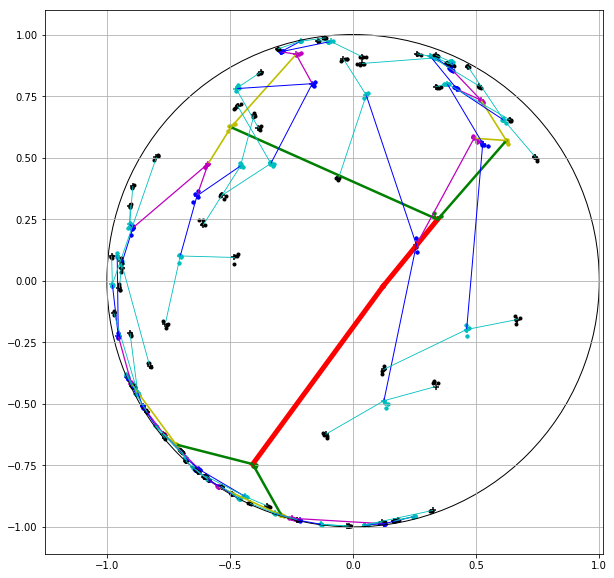

 19%|█▉        | 19/100 [00:00<00:00, 182.50it/s]

Average distortion: Tree: 0.584193766117096, All, nan


100%|██████████| 100/100 [00:00<00:00, 154.17it/s]


[Epoch 4] Recon Loss: 1797.7391357421875, MMD: 0.07313013821840286
Mean: [-0.15436548  0.7650873 ], "Var": [0.24223535]


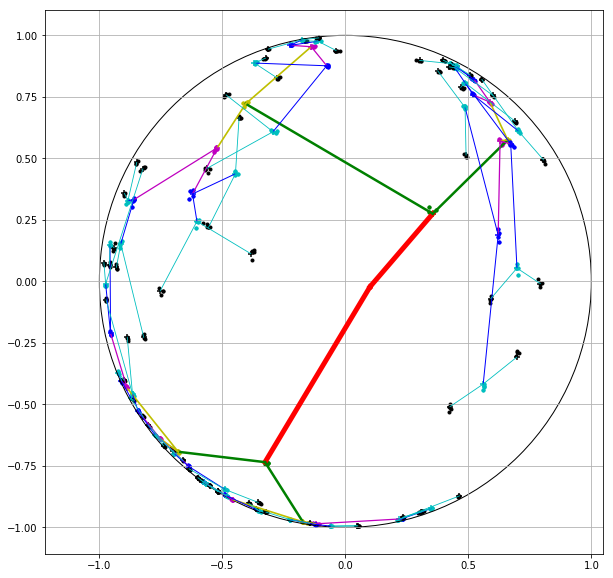

 22%|██▏       | 22/100 [00:00<00:00, 217.15it/s]

Average distortion: Tree: 0.5862925052642822, All, nan


100%|██████████| 100/100 [00:00<00:00, 199.19it/s]


[Epoch 5] Recon Loss: 1767.06201171875, MMD: 0.07774868607521057
Mean: [-0.14401764  0.8126982 ], "Var": [0.21222994]


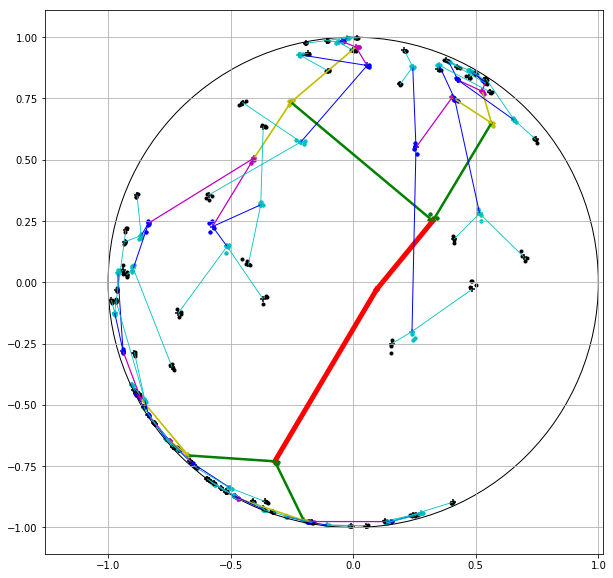

 18%|█▊        | 18/100 [00:00<00:00, 179.86it/s]

Average distortion: Tree: 0.5817286372184753, All, nan


100%|██████████| 100/100 [00:00<00:00, 184.11it/s]


[Epoch 6] Recon Loss: 1738.378173828125, MMD: 0.08416327834129333
Mean: [-0.07968392  0.8375224 ], "Var": [0.22341351]


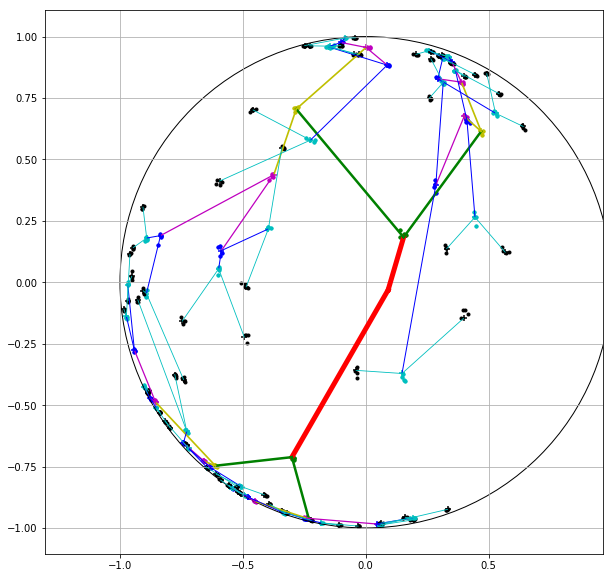

 14%|█▍        | 14/100 [00:00<00:00, 139.29it/s]

Average distortion: Tree: 0.5847833156585693, All, nan


100%|██████████| 100/100 [00:00<00:00, 164.99it/s]


[Epoch 7] Recon Loss: 1711.510009765625, MMD: 0.08310350775718689
Mean: [-0.03639141  0.8564685 ], "Var": [0.18990564]


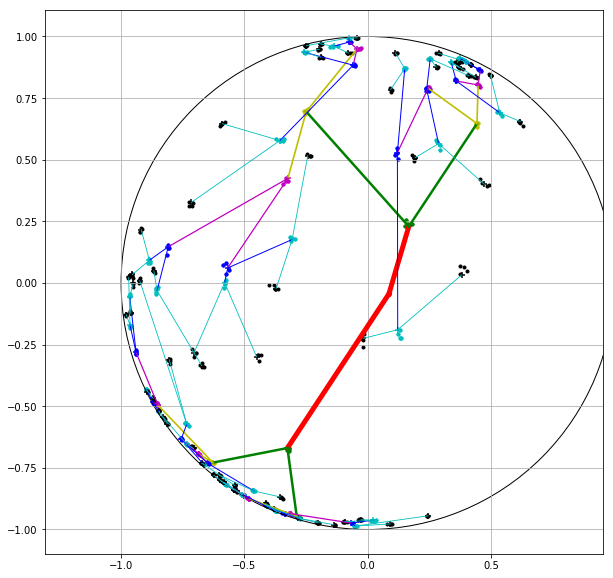

 14%|█▍        | 14/100 [00:00<00:00, 137.16it/s]

Average distortion: Tree: 0.5979194641113281, All, nan


100%|██████████| 100/100 [00:00<00:00, 152.90it/s]


[Epoch 8] Recon Loss: 1700.3233642578125, MMD: 0.06339514255523682
Mean: [-0.1904437  0.8441723], "Var": [0.19672388]


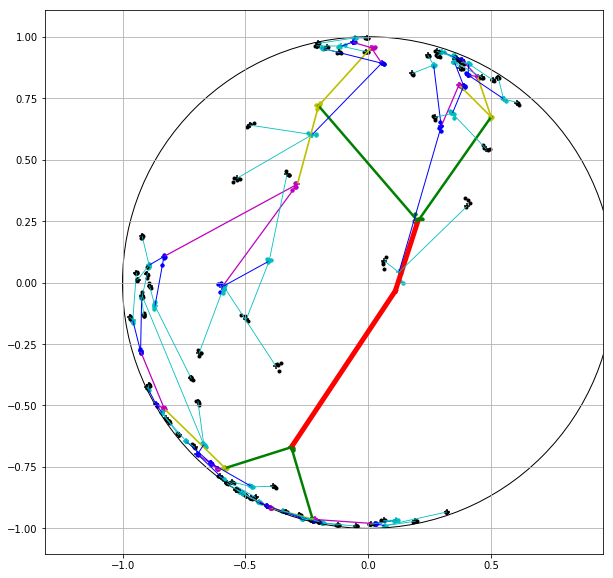

 20%|██        | 20/100 [00:00<00:00, 195.56it/s]

Average distortion: Tree: 0.5947362184524536, All, nan


100%|██████████| 100/100 [00:00<00:00, 179.30it/s]


[Epoch 9] Recon Loss: 1679.0301513671875, MMD: 0.09047114849090576
Mean: [-0.13455582  0.85796857], "Var": [0.20219867]


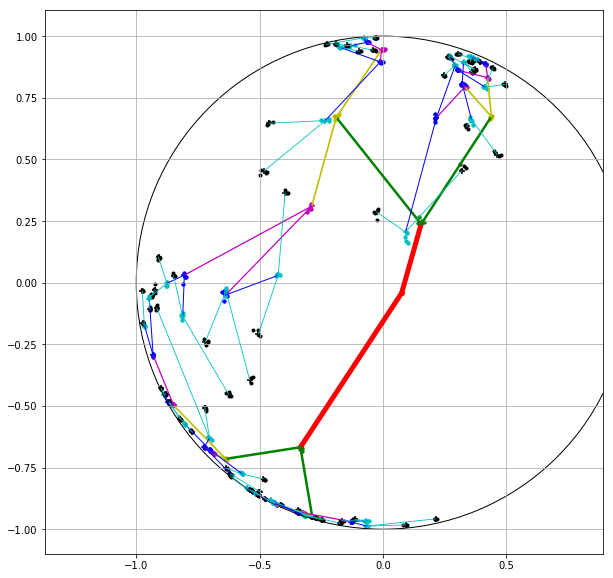

 17%|█▋        | 17/100 [00:00<00:00, 167.77it/s]

Average distortion: Tree: 0.6176972985267639, All, nan


100%|██████████| 100/100 [00:00<00:00, 153.06it/s]


[Epoch 10] Recon Loss: 1660.663818359375, MMD: 0.07598838955163956
Mean: [-0.14446583  0.8663554 ], "Var": [0.21954858]


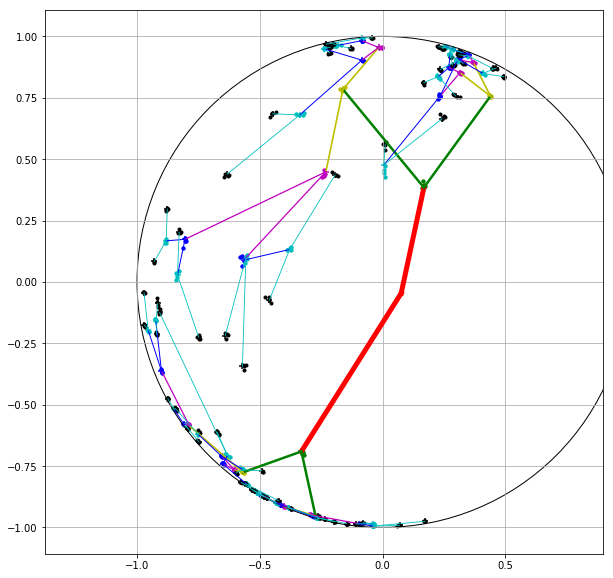

 17%|█▋        | 17/100 [00:00<00:00, 162.25it/s]

Average distortion: Tree: 0.6057611703872681, All, nan


100%|██████████| 100/100 [00:00<00:00, 170.58it/s]


[Epoch 11] Recon Loss: 1666.67822265625, MMD: 0.09473089873790741
Mean: [-0.17540704  0.854381  ], "Var": [0.21413274]


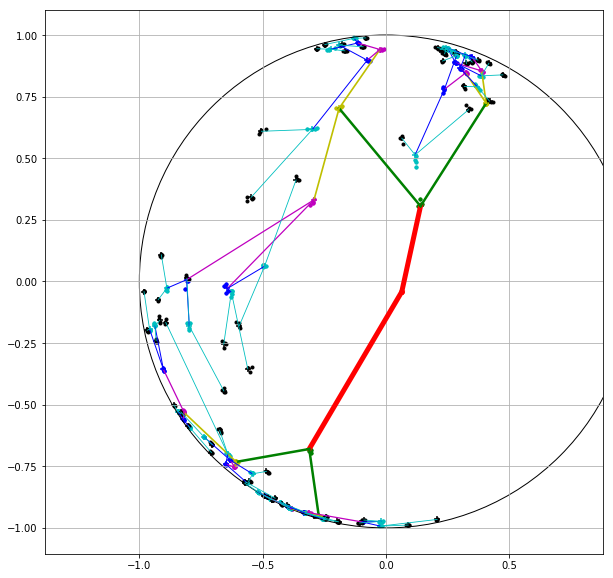

 17%|█▋        | 17/100 [00:00<00:00, 167.96it/s]

Average distortion: Tree: 0.604936420917511, All, nan


100%|██████████| 100/100 [00:00<00:00, 147.15it/s]


[Epoch 12] Recon Loss: 1672.7354736328125, MMD: 0.08574890345335007
Mean: [-0.13226788  0.84898734], "Var": [0.19547719]


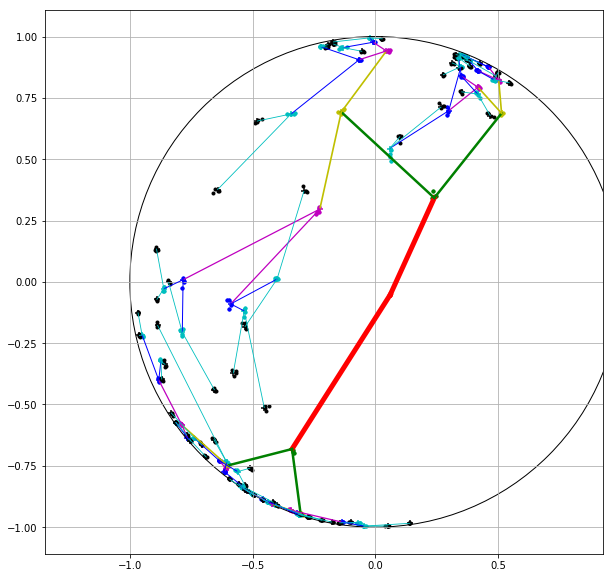

 17%|█▋        | 17/100 [00:00<00:00, 163.80it/s]

Average distortion: Tree: 0.6031584143638611, All, nan


100%|██████████| 100/100 [00:00<00:00, 164.56it/s]


[Epoch 13] Recon Loss: 1665.059814453125, MMD: 0.07582109421491623
Mean: [-0.18933952  0.8519787 ], "Var": [0.20088421]


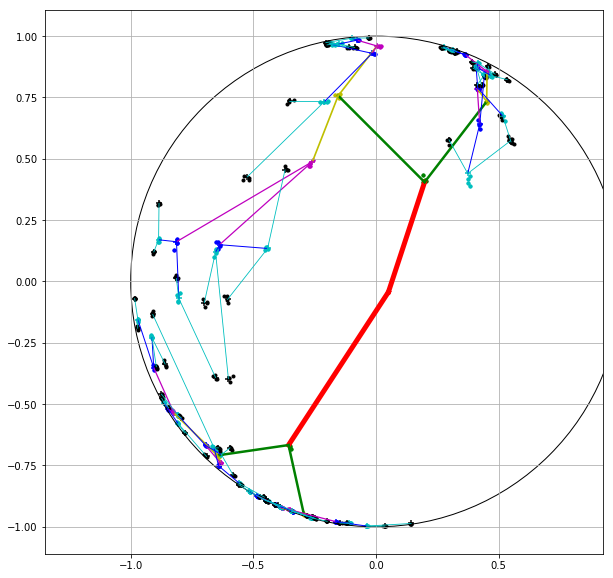

 19%|█▉        | 19/100 [00:00<00:00, 189.93it/s]

Average distortion: Tree: 0.5971139073371887, All, nan


100%|██████████| 100/100 [00:00<00:00, 160.63it/s]


[Epoch 14] Recon Loss: 1688.50341796875, MMD: 0.08113265037536621
Mean: [-0.0684401   0.83978754], "Var": [0.1999027]


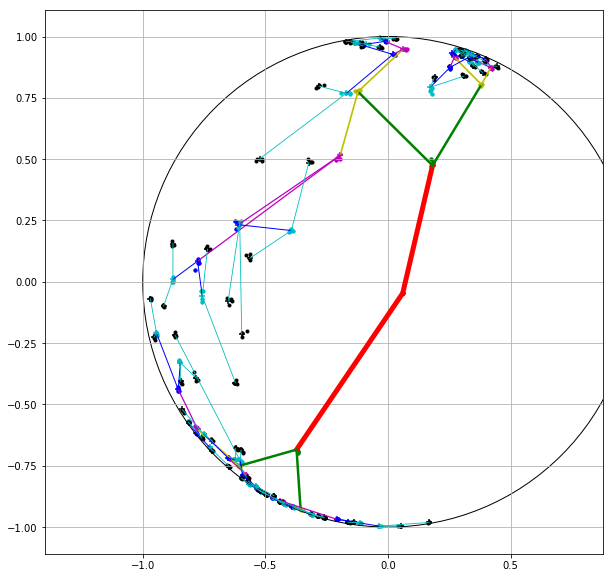

 17%|█▋        | 17/100 [00:00<00:00, 166.93it/s]

Average distortion: Tree: 0.6041460633277893, All, nan


100%|██████████| 100/100 [00:00<00:00, 177.26it/s]


[Epoch 15] Recon Loss: 1652.6114501953125, MMD: 0.08452195674180984
Mean: [-0.02674452  0.87108696], "Var": [0.20644931]


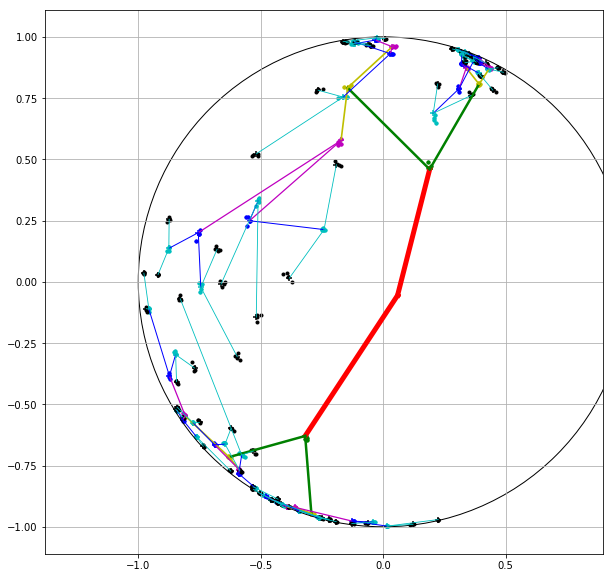

 20%|██        | 20/100 [00:00<00:00, 174.22it/s]

Average distortion: Tree: 0.5993781089782715, All, nan


100%|██████████| 100/100 [00:00<00:00, 189.55it/s]


[Epoch 16] Recon Loss: 1656.5198974609375, MMD: 0.09071654826402664
Mean: [-0.01858109  0.8653697 ], "Var": [0.17870714]


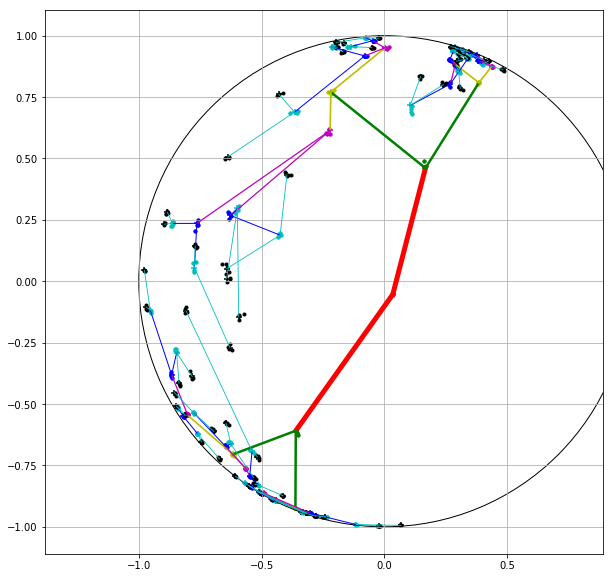

 18%|█▊        | 18/100 [00:00<00:00, 176.74it/s]

Average distortion: Tree: 0.6008226871490479, All, nan


100%|██████████| 100/100 [00:00<00:00, 147.45it/s]


[Epoch 17] Recon Loss: 1630.4176025390625, MMD: 0.0881023034453392
Mean: [-0.05682024  0.8765743 ], "Var": [0.18356489]


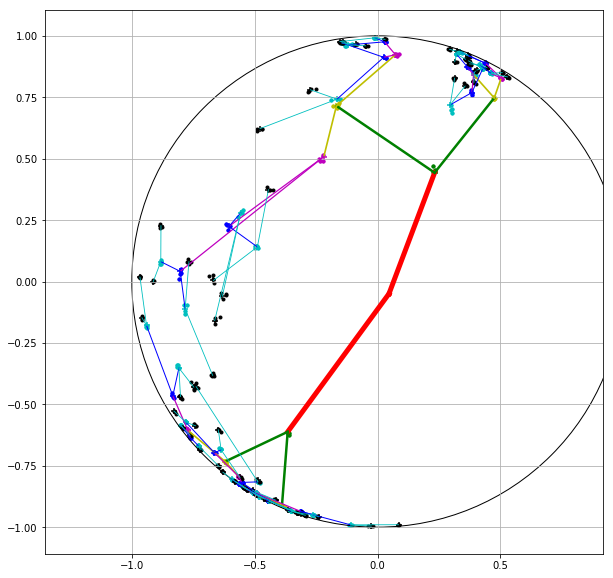

 20%|██        | 20/100 [00:00<00:00, 190.67it/s]

Average distortion: Tree: 0.6108431220054626, All, nan


100%|██████████| 100/100 [00:00<00:00, 175.43it/s]


[Epoch 18] Recon Loss: 1648.9334716796875, MMD: 0.08909904211759567
Mean: [-0.13282658  0.8608416 ], "Var": [0.18383043]


KeyboardInterrupt: 

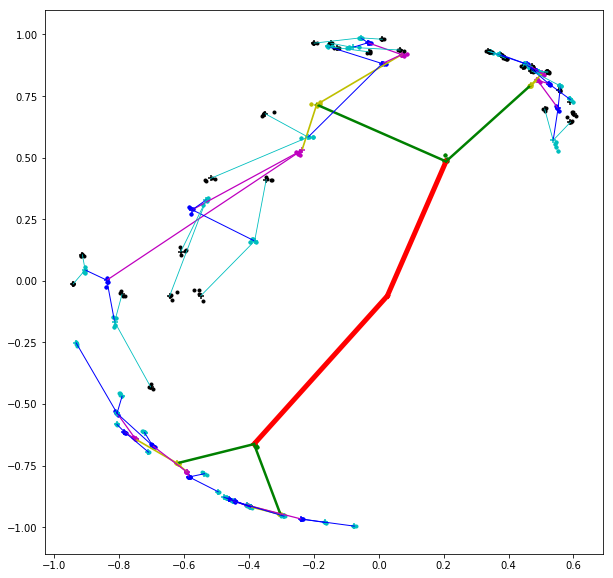

In [7]:
tf.reset_default_graph()
np.random.seed(4)
tf.set_random_seed(4)
opts = {}
opts['dataset'] = 'bd'
opts['input_dim'] = 50
if opts['dataset'] == 'nnlm':
    opts['input_dim'] = 128
opts['nw_type'] = 'simple'
opts['lr_adam'] = 1e-3
opts['lr_rsgd'] = 1e-3
opts['batch_size'] = 64
opts['nn_act_fn'] = tf.nn.tanh
opts['beta_mmd'] = 10.0
opts['sigma_mmd'] = 1.0 # Laplacian kernel width
opts['mmd_q'] = 1
opts['varregnorm'] = 2 # L1 or L2
opts['lambda_mmd'] = 1.0 # variance regularizer weight to avoid variance collapse
opts['beta_kld'] = 10.0
opts['dim_z'] = 2
opts['hyp_c'] = 1.0
opts['use_expmap'] = True
opts['hyp_var'] = False
opts['scalar_dispersion'] = True
opts['init_std'] = 0.01
opts['init_bias'] = 0.0
opts['prior_var'] = 1.7
opts['reparam_eucl'] = True
opts['b'] = 2
opts['treedepth'] = 6
opts['loss'] = 'l2' # l2 or bce loss
opts['recon_weight'] = 1.0
opts['c'] = 5
opts['dec_mlr'] = False
opts['enc_act_mu'] = None #tf.nn.tanh #lambda x: tf.nn.leaky_relu(x,alpha=0.2)
opts['enc_act_sigma'] = None #tf.nn.tanh

print(opts)
if opts['dataset'] == 'bd':
    X_train, X_train_flat, X_test = generate_tree_dataset(n_train=10,n_test=10,scale=1/opts['c'],
                                        treedepth=opts['treedepth'],b=opts['b'],c=opts['c'],d=opts['input_dim'],offset=5,
                                                     strict_norms=True,center=True)
    #X_embedded = TSNE(n_components=2,verbose=1).fit_transform(X_train_flat)
    #draw_latent_tree_tsne(opts,X_embedded,treedepth=opts['treedepth'],b=2,c=opts['c'],d=2,subset_len=1,plot_means=False)
    model = trainer(opts, data=X_train_flat, 
                visdata_train=X_train, visdata_test=X_test, epoch=1000, nr_samples=len(X_train_flat), shuffle=False) 
else:
    X_train, X_test = load_wordnet_data('nnlm')
    model = trainer(opts, data=X_train, 
                visdata_train=X_train, visdata_test=X_test, epoch=1000, nr_samples=len(X_train), shuffle=False) 


In [ ]:
X_train, X_train_flat, X_test = generate_tree_dataset(n_train=10,n_test=10,scale=1,
                                        treedepth=6,b=2,c=1,d=2,offset=5,
                                                     strict_norms=True,center=True)

# test exp and logmap
X_train_pd = np_exp_map(X_train_flat)
X_logmap = np_log_map(X_train_pd)
draw_latent_tree_tsne(opts,X_train_flat,treedepth=6,b=2,c=1,d=2,subset_len=1,plot_means=False)
draw_latent_tree_tsne(opts,X_train_pd,treedepth=6,b=2,c=1,d=2,subset_len=1,plot_means=False)
draw_latent_tree_tsne(opts,X_logmap,treedepth=6,b=2,c=1,d=2,subset_len=1,plot_means=False)

print(np.max(X_train_flat))

In [ ]:
draw_means(opts,X_train,model,treedepth=opts['treedepth'],
                             b=2,c=opts['c'],d=opts['input_dim'],subset_len=10)
draw_latent_tree(opts,X_train,model,treedepth=opts['treedepth'],
                             b=2,c=opts['c'],d=opts['input_dim'],subset_len=10,plot_means=False)